Impotar as bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os
import re

Carregamento do dataset

In [2]:
from google.colab import files

uploaded = files.upload()

Saving projetinhoHigh-resolution-AI-Data-Center-Training-Workloads-Dataset_FigShare.zip to projetinhoHigh-resolution-AI-Data-Center-Training-Workloads-Dataset_FigShare.zip


In [3]:
nome_zip = list(uploaded.keys())[0]

with zipfile.ZipFile(nome_zip, 'r') as zip_ref:
    zip_ref.extractall('dataset')

print("Dataset extraído com sucesso!")

Dataset extraído com sucesso!


In [4]:
arquivos = []

for raiz, pastas, nomes in os.walk('dataset'):
    for nome in nomes:
        if nome.lower().endswith('.csv') and 'Node_Dataset' in raiz:
            arquivos.append(os.path.join(raiz, nome))

print("Quantidade de arquivos encontrados:", len(arquivos))

Quantidade de arquivos encontrados: 42


In [5]:
arquivos_unicos = {}

for arquivo in arquivos:
    nome = os.path.basename(arquivo)
    if nome not in arquivos_unicos:
        arquivos_unicos[nome] = arquivo

arquivos = list(arquivos_unicos.values())

print("Arquivos únicos:", len(arquivos))

Arquivos únicos: 32


In [6]:
dados = []

for arquivo in arquivos:
    df_temp = pd.read_csv(arquivo)

    novo = pd.DataFrame()

    novo['cpu_utilization_percent'] = df_temp['cpu_utilization_percent']
    novo['cpu_freq_MHz'] = df_temp['cpu_freq_MHz']
    novo['cpu_power_W'] = df_temp['cpu_power_W']
    novo['cpu_temp_C'] = df_temp['cpu_temp_C']

    novo['gpu_utilization_mean'] = df_temp[
        [f'gpu{i}_utilization_percent' for i in range(8)]
    ].mean(axis=1)

    novo['gpu_mem_utilization_mean'] = df_temp[
        [f'gpu{i}_mem_utilization' for i in range(8)]
    ].mean(axis=1)

    novo['gpu_mem_used_mean_MB'] = df_temp[
        [f'gpu{i}_mem_used_MB' for i in range(8)]
    ].mean(axis=1)

    novo['gpu_temp_mean_C'] = df_temp[
        [f'gpu{i}_temp_C' for i in range(8)]
    ].mean(axis=1)

    novo['total_gpu_power_W'] = df_temp[
        [f'gpu{i}_power_W' for i in range(8)]
    ].sum(axis=1)

    nome = os.path.basename(arquivo)

    novo['gpu_model'] = 'B200' if 'B200' in nome else 'H100'
    novo['workload'] = 'LLM' if nome.startswith('LLM_') else 'Image Generation'

    batch = re.search(r'BatchSize(\d+)', nome)
    novo['batch_size'] = int(batch.group(1)) if batch else np.nan

    dados.append(novo)

df = pd.concat(dados, ignore_index=True)

print("Base criada com sucesso!")
print("Linhas:", df.shape[0])
print("Colunas:", df.shape[1])

Base criada com sucesso!
Linhas: 1440000
Colunas: 12


3. EDA Documentada
Conhecendo o dataset

In [7]:
df.head()

,cpu_utilization_percent,cpu_freq_MHz,cpu_power_W,cpu_temp_C,gpu_utilization_mean,gpu_mem_utilization_mean,gpu_mem_used_mean_MB,gpu_temp_mean_C,total_gpu_power_W,gpu_model,workload,batch_size
0,3.4,2000.0,NaN,NaN,88.0,0.0,9741.75,38.625,1146.110,H100,Image Generation,128
1,4.4,2000.0,NaN,NaN,88.0,0.0,9741.75,38.500,1113.274,H100,Image Generation,128
2,3.9,2000.0,NaN,NaN,88.0,0.0,9741.75,38.500,1101.380,H100,Image Generation,128
3,4.1,2000.0,NaN,NaN,88.0,0.0,9741.75,38.500,1084.403,H100,Image Generation,128
4,3.9,2000.0,NaN,NaN,88.0,0.0,9741.75,38.500,1042.592,H100,Image Generation,128


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440000 entries, 0 to 1439999
Data columns (total 12 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   cpu_utilization_percent   1440000 non-null  float64
 1   cpu_freq_MHz              1440000 non-null  float64
 2   cpu_power_W               0 non-null        float64
 3   cpu_temp_C                0 non-null        float64
 4   gpu_utilization_mean      1440000 non-null  float64
 5   gpu_mem_utilization_mean  1440000 non-null  float64
 6   gpu_mem_used_mean_MB      1440000 non-null  float64
 7   gpu_temp_mean_C           1440000 non-null  float64
 8   total_gpu_power_W         1440000 non-null  float64
 9   gpu_model                 1440000 non-null  object 
 10  workload                  1440000 non-null  object 
 11  batch_size                1440000 non-null  int64  
dtypes: float64(9), int64(1), object(2)
memory usage: 131.8+ MB


In [9]:
df.shape

(1440000, 12)

A base final contém 1.440.000 registros e 12 variáveis relacionadas ao uso de CPU, GPU, memória, temperatura, modelo de GPU, tipo de carga de IA e potência elétrica consumida pelas GPUs.

* Verificação de valores ausentes

In [10]:
df.isnull().sum()


,0
cpu_utilization_percent,0
cpu_freq_MHz,0
cpu_power_W,1440000
cpu_temp_C,1440000
gpu_utilization_mean,0
gpu_mem_utilization_mean,0
gpu_mem_used_mean_MB,0
gpu_temp_mean_C,0
total_gpu_power_W,0
gpu_model,0


In [11]:
(df.isnull().sum() / len(df)) * 100

,0
cpu_utilization_percent,0.0
cpu_freq_MHz,0.0
cpu_power_W,100.0
cpu_temp_C,100.0
gpu_utilization_mean,0.0
gpu_mem_utilization_mean,0.0
gpu_mem_used_mean_MB,0.0
gpu_temp_mean_C,0.0
total_gpu_power_W,0.0
gpu_model,0.0


Foi realizada a verificação de valores ausentes no conjunto de dados. As variáveis relacionadas à potência e temperatura da CPU apresentam ausência de dados, enquanto as demais variáveis principais possuem registros disponíveis para a análise.

* Estatísticas descritivas

In [12]:
df.describe()

,cpu_utilization_percent,cpu_freq_MHz,cpu_power_W,cpu_temp_C,gpu_utilization_mean,gpu_mem_utilization_mean,gpu_mem_used_mean_MB,gpu_temp_mean_C,total_gpu_power_W,batch_size
count,1.440000e+06,1.440000e+06,0.0,0.0,1.440000e+06,1.440000e+06,1.440000e+06,1.440000e+06,1.440000e+06,1.440000e+06
mean,1.090127e+01,1.950000e+03,NaN,NaN,7.147882e+01,1.882748e+01,4.119126e+04,4.661377e+01,3.499316e+03,9.712500e+01
std,1.947126e+01,5.000002e+01,NaN,NaN,3.848158e+01,1.831711e+01,2.119683e+04,8.906507e+00,1.941566e+03,1.278397e+02
min,0.000000e+00,1.900000e+03,NaN,NaN,0.000000e+00,0.000000e+00,9.741750e+03,3.025000e+01,9.668170e+02,2.000000e+00
25%,4.100000e+00,1.900000e+03,NaN,NaN,6.037500e+01,0.000000e+00,2.692406e+04,3.887500e+01,1.587603e+03,1.600000e+01
50%,4.100000e+00,1.950000e+03,NaN,NaN,8.812500e+01,1.737500e+01,3.405538e+04,4.550000e+01,3.289006e+03,2.400000e+01
75%,5.100000e+00,2.000000e+03,NaN,NaN,9.900000e+01,3.162500e+01,5.386550e+04,5.575000e+01,5.015836e+03,1.280000e+02
max,1.000000e+02,2.000000e+03,NaN,NaN,1.000000e+02,7.075000e+01,1.113384e+05,6.412500e+01,7.669471e+03,5.120000e+02


In [13]:
df['total_gpu_power_W'].describe()

,total_gpu_power_W
count,1.440000e+06
mean,3.499316e+03
std,1.941566e+03
min,9.668170e+02
25%,1.587603e+03
50%,3.289006e+03
75%,5.015836e+03
max,7.669471e+03


A potência total das GPUs apresentou média de aproximadamente 3.499 W e mediana de 3.289 W. Os valores variaram de aproximadamente 967 W a 7.669 W, mostrando que a demanda energética varia bastante entre as cargas de Inteligência Artificial.

* Distribuição da potência das GPUs

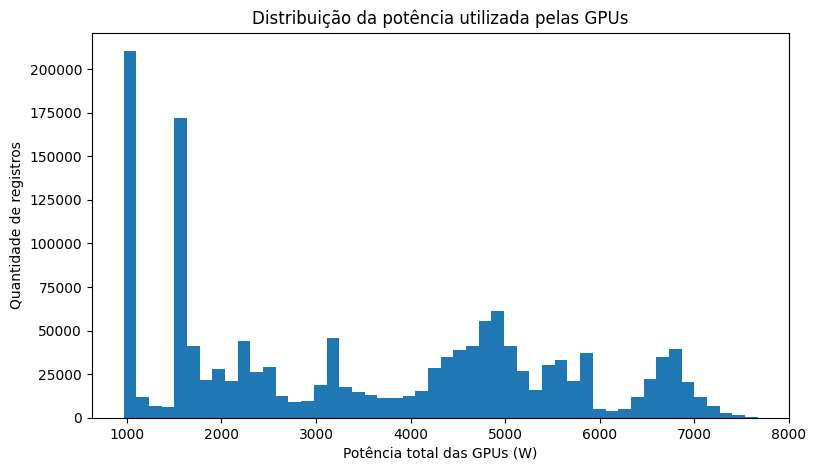

In [14]:
plt.figure(figsize=(9, 5))

plt.hist(df['total_gpu_power_W'], bins=50)

plt.xlabel('Potência total das GPUs (W)')
plt.ylabel('Quantidade de registros')
plt.title('Distribuição da potência utilizada pelas GPUs')

plt.show()

O gráfico mostra que a potência utilizada pelas GPUs varia bastante entre os registros. Isso indica que diferentes cargas de Inteligência Artificial podem exigir níveis diferentes de energia, o que reforça a importância de tentar prever esse consumo.






 * Potência média por modelo de GPU

In [15]:
media_gpu = df.groupby('gpu_model')['total_gpu_power_W'].mean()

media_gpu

,total_gpu_power_W
gpu_model,
B200,4034.816800
H100,2963.814989


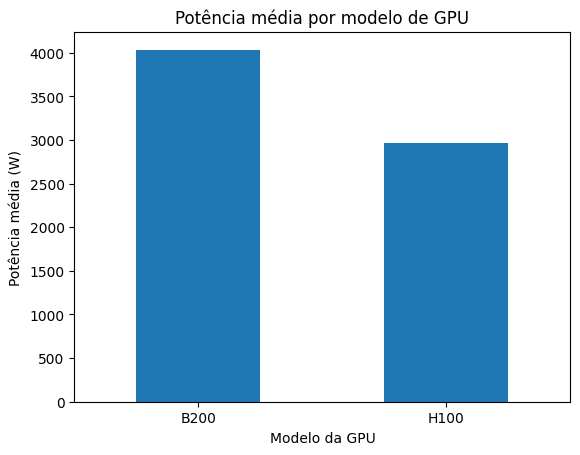

In [16]:
media_gpu.plot(kind='bar')

plt.xlabel('Modelo da GPU')
plt.ylabel('Potência média (W)')
plt.title('Potência média por modelo de GPU')
plt.xticks(rotation=0)

plt.show()

A GPU B200 apresentou potência média de aproximadamente 4.035 W, enquanto a H100 apresentou aproximadamente 2.964 W. Isso mostra que, nos experimentos analisados, o modelo B200 apresentou maior demanda média de potência.

* Potência média por tipo de carga de IA

In [17]:
media_carga = df.groupby('workload')['total_gpu_power_W'].mean()

media_carga

,total_gpu_power_W
workload,
Image Generation,2579.815007
LLM,4214.483252


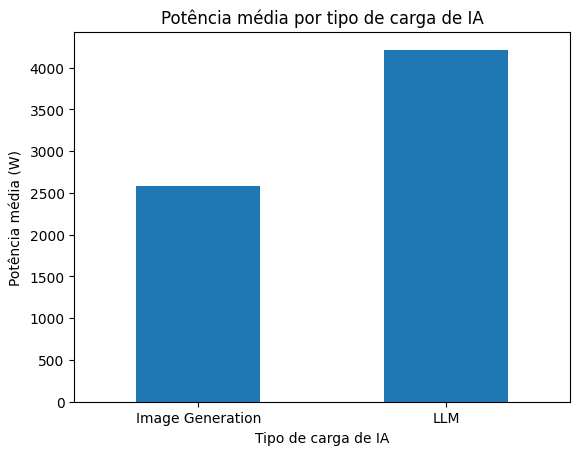

In [18]:
media_carga.plot(kind='bar')

plt.xlabel('Tipo de carga de IA')
plt.ylabel('Potência média (W)')
plt.title('Potência média por tipo de carga de IA')
plt.xticks(rotation=0)

plt.show()

Os resultados mostram que as cargas de LLM apresentaram maior potência média do que as cargas de geração de imagens. Isso indica que o tipo de aplicação de Inteligência Artificial pode influenciar a demanda energética durante a execução.

* Relação entre utilização da GPU e potência

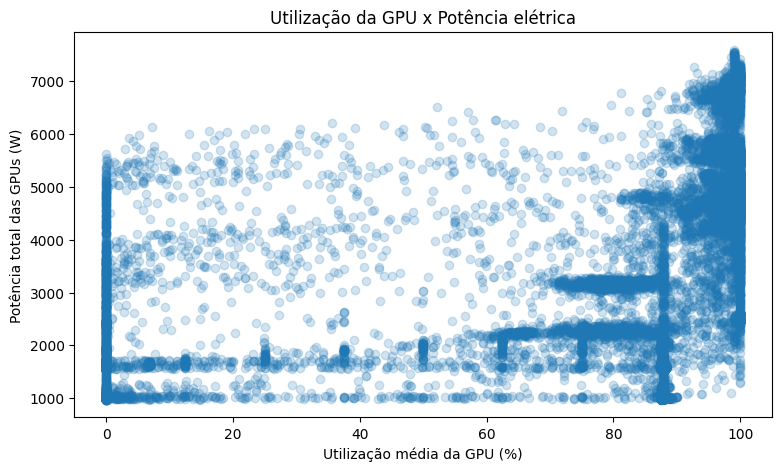

In [19]:
amostra = df.sample(20000, random_state=42)

plt.figure(figsize=(9, 5))

plt.scatter(
    amostra['gpu_utilization_mean'],
    amostra['total_gpu_power_W'],
    alpha=0.2
)

plt.xlabel('Utilização média da GPU (%)')
plt.ylabel('Potência total das GPUs (W)')
plt.title('Utilização da GPU x Potência elétrica')

plt.show()

O gráfico indica uma tendência de aumento da potência elétrica conforme cresce a utilização da GPU. Isso sugere que cargas que utilizam mais intensamente o hardware tendem a exigir maior potência elétrica.

* Análise de correlação

In [20]:
numericas = df.select_dtypes(include=np.number)

correlacao = numericas.corr()

correlacao['total_gpu_power_W'].sort_values(ascending=False)

,total_gpu_power_W
total_gpu_power_W,1.000000
gpu_temp_mean_C,0.800225
gpu_mem_utilization_mean,0.675733
gpu_utilization_mean,0.564127
gpu_mem_used_mean_MB,0.346966
cpu_utilization_percent,-0.252513
cpu_freq_MHz,-0.275809
batch_size,-0.351483
cpu_power_W,NaN
cpu_temp_C,NaN





A temperatura média da GPU apresentou a maior correlação positiva com a potência consumida, cerca de 0,80. A utilização da memória da GPU apresentou correlação de aproximadamente 0,68 e a utilização média da GPU cerca de 0,56. Isso indica que essas variáveis possuem relação relevante com a potência elétrica das GPUs e podem contribuir para a previsão do consumo.


* Tratamento dos Dados

In [21]:
colunas_vazias = [col for col in df.columns if df[col].isnull().all()]

print("Colunas totalmente vazias:", colunas_vazias)

df = df.drop(columns=colunas_vazias)

print("Novo formato da base:", df.shape)

Colunas totalmente vazias: ['cpu_power_W', 'cpu_temp_C']
Novo formato da base: (1440000, 10)


As colunas cpu_power_W e cpu_temp_C foram removidas porque apresentavam 100% de valores ausentes. Como não havia informações disponíveis nessas variáveis, elas não poderiam contribuir para a análise nem para os modelos de Machine Learning.

* Verificação de registros duplicados

In [22]:
duplicados = df.duplicated().sum()

print("Quantidade de registros duplicados:", duplicados)
print("Percentual de duplicados:", (duplicados / len(df)) * 100)

Quantidade de registros duplicados: 18506
Percentual de duplicados: 1.285138888888889


Foram encontrados 18.506 registros duplicados, representando aproximadamente 1,29% da base. Como os dados representam medições sucessivas de cargas de Inteligência Artificial, valores idênticos podem ocorrer naturalmente em momentos diferentes. Por isso, esses registros foram mantidos.

* Identificação de outliers

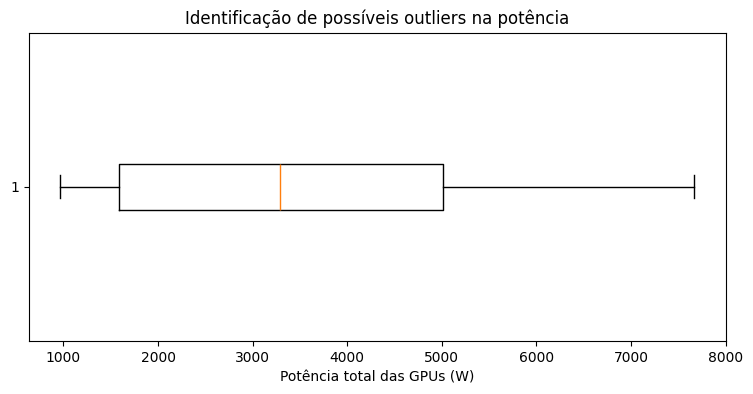

In [23]:
plt.figure(figsize=(9, 4))

plt.boxplot(df['total_gpu_power_W'], vert=False)

plt.xlabel('Potência total das GPUs (W)')
plt.title('Identificação de possíveis outliers na potência')

plt.show()


In [24]:
Q1 = df['total_gpu_power_W'].quantile(0.25)
Q3 = df['total_gpu_power_W'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[
    (df['total_gpu_power_W'] < limite_inferior) |
    (df['total_gpu_power_W'] > limite_superior)
]

print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)
print("Quantidade de possíveis outliers:", len(outliers))
print("Percentual:", (len(outliers) / len(df)) * 100)

Limite inferior: -3554.74575
Limite superior: 10158.18425
Quantidade de possíveis outliers: 0
Percentual: 0.0


Foi utilizado o método IQR para identificar possíveis valores extremos na potência das GPUs. Não foram encontrados outliers segundo esse critério, portanto nenhum registro foi removido nesta etapa.

* Codificação das variáveis categóricas

In [25]:
df_encoded = pd.get_dummies(
    df,
    columns=['gpu_model', 'workload'],
    dtype=int
)

df_encoded.head()

,cpu_utilization_percent,cpu_freq_MHz,gpu_utilization_mean,gpu_mem_utilization_mean,gpu_mem_used_mean_MB,gpu_temp_mean_C,total_gpu_power_W,batch_size,gpu_model_B200,gpu_model_H100,workload_Image Generation,workload_LLM
0,3.4,2000.0,88.0,0.0,9741.75,38.625,1146.110,128,0,1,1,0
1,4.4,2000.0,88.0,0.0,9741.75,38.500,1113.274,128,0,1,1,0
2,3.9,2000.0,88.0,0.0,9741.75,38.500,1101.380,128,0,1,1,0
3,4.1,2000.0,88.0,0.0,9741.75,38.500,1084.403,128,0,1,1,0
4,3.9,2000.0,88.0,0.0,9741.75,38.500,1042.592,128,0,1,1,0


As variáveis gpu_model e workload foram transformadas utilizando One-Hot Encoding. Esse método foi escolhido porque essas categorias não possuem uma ordem natural entre si, permitindo convertê-las em valores numéricos sem criar uma hierarquia artificial.

In [26]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440000 entries, 0 to 1439999
Data columns (total 12 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   cpu_utilization_percent    1440000 non-null  float64
 1   cpu_freq_MHz               1440000 non-null  float64
 2   gpu_utilization_mean       1440000 non-null  float64
 3   gpu_mem_utilization_mean   1440000 non-null  float64
 4   gpu_mem_used_mean_MB       1440000 non-null  float64
 5   gpu_temp_mean_C            1440000 non-null  float64
 6   total_gpu_power_W          1440000 non-null  float64
 7   batch_size                 1440000 non-null  int64  
 8   gpu_model_B200             1440000 non-null  int64  
 9   gpu_model_H100             1440000 non-null  int64  
 10  workload_Image Generation  1440000 non-null  int64  
 11  workload_LLM               1440000 non-null  int64  
dtypes: float64(7), int64(5)
memory usage: 131.8 MB


* Divisão dos dados em treino e teste

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop(columns=['total_gpu_power_W'])
y = df_encoded['total_gpu_power_W']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)



Os dados foram divididos em 80% para treinamento e 20% para teste. Essa divisão permite treinar os modelos em uma parte da base e avaliar seu desempenho em dados que não foram utilizados durante o treinamento.

* Escalonamento das variáveis numéricas

In [28]:
colunas_escalar = [
    'cpu_utilization_percent',
    'cpu_freq_MHz',
    'gpu_utilization_mean',
    'gpu_mem_utilization_mean',
    'gpu_mem_used_mean_MB',
    'gpu_temp_mean_C',
    'batch_size'
]

scaler = StandardScaler()

X_train[colunas_escalar] = scaler.fit_transform(
    X_train[colunas_escalar]
)

X_test[colunas_escalar] = scaler.transform(
    X_test[colunas_escalar]
)

As variáveis numéricas foram padronizadas utilizando o StandardScaler, permitindo que atributos com diferentes escalas possam ser utilizados de forma adequada pelos modelos de Machine Learning. O escalonamento foi ajustado apenas nos dados de treinamento para evitar vazamento de informações dos dados de teste.

In [29]:
X_train.head()

,cpu_utilization_percent,cpu_freq_MHz,gpu_utilization_mean,gpu_mem_utilization_mean,gpu_mem_used_mean_MB,gpu_temp_mean_C,batch_size,gpu_model_B200,gpu_model_H100,workload_Image Generation,workload_LLM
909259,-0.364553,0.999911,0.611055,1.305511,-0.783815,0.323618,-0.634868,0,1,0,1
531608,2.112732,-1.000089,-1.858248,-1.027807,-0.663603,-1.444910,0.241289,1,0,1,0
808775,-0.359413,0.999911,0.435605,-0.604808,-0.731634,-0.672933,-0.744388,0,1,0,1
738345,-0.359413,0.999911,0.741019,1.387382,0.595804,1.221918,-0.634868,0,1,0,1
1347313,4.579739,-1.000089,0.607806,0.138852,-0.503544,0.407834,-0.634868,1,0,0,1


In [30]:
X_train[colunas_escalar].mean().round(3)

,0
cpu_utilization_percent,0.0
cpu_freq_MHz,-0.0
gpu_utilization_mean,0.0
gpu_mem_utilization_mean,0.0
gpu_mem_used_mean_MB,0.0
gpu_temp_mean_C,-0.0
batch_size,-0.0


* verificação final dos dados tratados


In [31]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1152000, 11)
X_test: (288000, 11)
y_train: (1152000,)
y_test: (288000,)


In [32]:
print("Valores ausentes no treino:", X_train.isnull().sum().sum())
print("Valores ausentes no teste:", X_test.isnull().sum().sum())

Valores ausentes no treino: 0
Valores ausentes no teste: 0


In [33]:
X_train.head()

,cpu_utilization_percent,cpu_freq_MHz,gpu_utilization_mean,gpu_mem_utilization_mean,gpu_mem_used_mean_MB,gpu_temp_mean_C,batch_size,gpu_model_B200,gpu_model_H100,workload_Image Generation,workload_LLM
909259,-0.364553,0.999911,0.611055,1.305511,-0.783815,0.323618,-0.634868,0,1,0,1
531608,2.112732,-1.000089,-1.858248,-1.027807,-0.663603,-1.444910,0.241289,1,0,1,0
808775,-0.359413,0.999911,0.435605,-0.604808,-0.731634,-0.672933,-0.744388,0,1,0,1
738345,-0.359413,0.999911,0.741019,1.387382,0.595804,1.221918,-0.634868,0,1,0,1
1347313,4.579739,-1.000089,0.607806,0.138852,-0.503544,0.407834,-0.634868,1,0,0,1


Após o tratamento, a base foi dividida em conjuntos de treinamento e teste e não apresentou valores ausentes. As variáveis numéricas foram escalonadas corretamente, deixando os dados preparados para as próximas etapas de Machine Learning.

Baseline

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

media_treino = y_train.mean()

y_pred_baseline = np.full(len(y_test), media_treino)

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_baseline = r2_score(y_test, y_pred_baseline)

print("Baseline")
print("MAE:", mae_baseline)
print("RMSE:", rmse_baseline)
print("R²:", r2_baseline)

Baseline
MAE: 1744.9984361152785
RMSE: 1941.477619581479
R²: -5.670577118976894e-08


O baseline foi utilizado como referência inicial para comparar o desempenho dos modelos de Machine Learning. Como ele prevê sempre a média da potência do conjunto de treinamento, seu R² ficou próximo de zero, mostrando que sozinho ele não consegue explicar a variação da potência consumida.

Regressão Linear

In [35]:
from sklearn.linear_model import LinearRegression

modelo_lr = LinearRegression()

modelo_lr.fit(X_train, y_train)

y_pred_lr = modelo_lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Regressão Linear")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R²:", r2_lr)

Regressão Linear
MAE: 562.2774220613804
RMSE: 765.5769265575353
R²: 0.8445062564870326


A Regressão Linear foi utilizada por ser um modelo simples e adequado para previsão de valores contínuos. Seu desempenho será comparado ao baseline e aos demais algoritmos.

Random Forest Regressor

In [36]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

y_pred_rf = modelo_rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

Random Forest
MAE: 167.36701079585728
RMSE: 340.0778587295153
R²: 0.9693174138411464


O Random Forest foi escolhido por conseguir capturar relações mais complexas e não lineares entre as características das cargas de IA e a potência consumida. O Random Forest apresentou desempenho superior à Regressão Linear, com R² de aproximadamente 0,97 e erros menores. Isso indica que o modelo conseguiu representar melhor as relações entre as variáveis e a potência consumida.

Gradient Boosting Regressor

In [37]:
from sklearn.ensemble import GradientBoostingRegressor

modelo_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modelo_gb.fit(X_train, y_train)

y_pred_gb = modelo_gb.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting")
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R²:", r2_gb)

Gradient Boosting
MAE: 374.242302368152
RMSE: 590.8148369889323
R²: 0.9073942328726942


O Gradient Boosting foi escolhido por construir modelos de forma sequencial, buscando corrigir os erros cometidos nas etapas anteriores e capturar relações complexas entre as variáveis.

Comparação dos modelos

In [38]:
resultados = pd.DataFrame({
    'Modelo': [
        'Baseline',
        'Regressão Linear',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        mae_baseline,
        mae_lr,
        mae_rf,
        mae_gb
    ],
    'RMSE': [
        rmse_baseline,
        rmse_lr,
        rmse_rf,
        rmse_gb
    ],
    'R²': [
        r2_baseline,
        r2_lr,
        r2_rf,
        r2_gb
    ]
})

resultados

,Modelo,MAE,RMSE,R²
0,Baseline,1744.998436,1941.477620,-5.670577e-08
1,Regressão Linear,562.277422,765.576927,8.445063e-01
2,Random Forest,167.367011,340.077859,9.693174e-01
3,Gradient Boosting,374.242302,590.814837,9.073942e-01


O Random Forest apresentou o melhor desempenho entre os modelos avaliados, com menor MAE e RMSE e maior R². Por esse motivo, ele foi selecionado para a etapa de ajuste de hiperparâmetros.

Ajuste de hiperparâmetros do Random Forest

In [39]:
from sklearn.model_selection import RandomizedSearchCV

X_amostra = X_train.sample(100000, random_state=42)
y_amostra = y_train.loc[X_amostra.index]

parametros = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

busca_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    parametros,
    n_iter=6,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

busca_rf.fit(X_amostra, y_amostra)

print("Melhores hiperparâmetros:")
print(busca_rf.best_params_)

Melhores hiperparâmetros:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 20}


O ajuste de hiperparâmetros foi realizado no Random Forest por ter apresentado o melhor desempenho na comparação dos modelos. Foram testadas diferentes configurações de número de árvores, profundidade e quantidade mínima de amostras. Foi utilizada uma amostra de 100 mil registros para reduzir o custo computacional da busca.

Random Forest ajustado

In [41]:
modelo_rf_final = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

modelo_rf_final.fit(X_train, y_train)

y_pred_rf_final = modelo_rf_final.predict(X_test)

mae_rf_final = mean_absolute_error(y_test, y_pred_rf_final)
rmse_rf_final = np.sqrt(mean_squared_error(y_test, y_pred_rf_final))
r2_rf_final = r2_score(y_test, y_pred_rf_final)

print("Random Forest Ajustado")
print("MAE:", mae_rf_final)
print("RMSE:", rmse_rf_final)
print("R²:", r2_rf_final)

Random Forest Ajustado
MAE: 150.6346419401152
RMSE: 317.13686061283744
R²: 0.97331736638034


Após o ajuste de hiperparâmetros, o Random Forest foi treinado novamente com a melhor configuração encontrada para verificar se houve melhoria no desempenho.

O Random Forest ajustado apresentou desempenho superior ao modelo inicial, com redução do MAE e do RMSE e aumento do R² para aproximadamente 0,973. Isso mostra que o ajuste dos hiperparâmetros contribuiu para melhorar a precisão das previsões.

Comparação final dos modelos

In [42]:
resultados_finais = pd.DataFrame({
    'Modelo': [
        'Baseline',
        'Regressão Linear',
        'Random Forest',
        'Gradient Boosting',
        'Random Forest Ajustado'
    ],
    'MAE': [
        mae_baseline,
        mae_lr,
        mae_rf,
        mae_gb,
        mae_rf_final
    ],
    'RMSE': [
        rmse_baseline,
        rmse_lr,
        rmse_rf,
        rmse_gb,
        rmse_rf_final
    ],
    'R²': [
        r2_baseline,
        r2_lr,
        r2_rf,
        r2_gb,
        r2_rf_final
    ]
})

resultados_finais

,Modelo,MAE,RMSE,R²
0,Baseline,1744.998436,1941.477620,-5.670577e-08
1,Regressão Linear,562.277422,765.576927,8.445063e-01
2,Random Forest,167.367011,340.077859,9.693174e-01
3,Gradient Boosting,374.242302,590.814837,9.073942e-01
4,Random Forest Ajustado,150.634642,317.136861,9.733174e-01


O Random Forest Ajustado apresentou o melhor desempenho entre os modelos avaliados, com o menor MAE e RMSE e o maior R². O modelo conseguiu explicar aproximadamente 97,3% da variação da potência consumida, sendo escolhido como modelo final do projeto.

8. Métricas justificadas

Foram utilizadas as métricas MAE, RMSE e R² porque o problema consiste em prever um valor numérico contínuo, a potência elétrica em watts. O MAE mostra o erro médio das previsões na mesma unidade da potência. O RMSE também mede o erro, mas dá maior peso aos erros mais altos. Já o R² indica quanto da variação da potência é explicada pelo modelo. Dessa forma, as três métricas permitem avaliar o desempenho dos modelos de diferentes perspectivas.

9. Explicabilidade do modelo

Para compreender quais características mais influenciam as previsões do Random Forest Ajustado, foi analisada a importância das variáveis utilizadas pelo modelo.

In [43]:
importancias = pd.DataFrame({
    'Variável': X_train.columns,
    'Importância': modelo_rf_final.feature_importances_
})

importancias = importancias.sort_values(
    by='Importância',
    ascending=False
)

importancias

,Variável,Importância
2,gpu_utilization_mean,0.641212
5,gpu_temp_mean_C,0.137493
3,gpu_mem_utilization_mean,0.084119
7,gpu_model_B200,0.062099
4,gpu_mem_used_mean_MB,0.022716
1,cpu_freq_MHz,0.018526
8,gpu_model_H100,0.018240
0,cpu_utilization_percent,0.008154
6,batch_size,0.005269
10,workload_LLM,0.001269


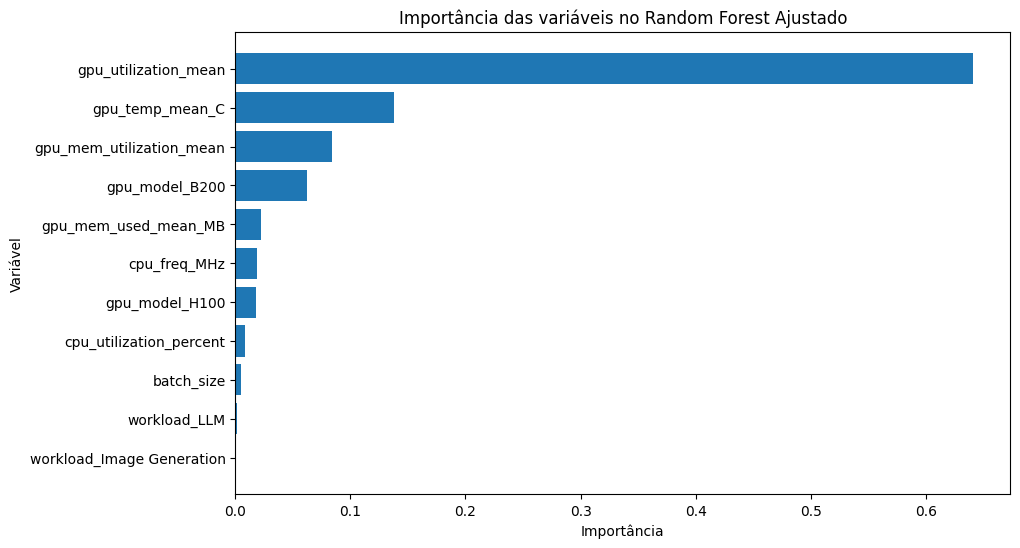

In [44]:
plt.figure(figsize=(10, 6))

plt.barh(
    importancias['Variável'],
    importancias['Importância']
)

plt.xlabel('Importância')
plt.ylabel('Variável')
plt.title('Importância das variáveis no Random Forest Ajustado')

plt.gca().invert_yaxis()

plt.show()

A análise de importância das variáveis mostrou que a utilização média da GPU foi a característica que mais influenciou as previsões do modelo, representando aproximadamente 64% da importância total. A temperatura média da GPU e a utilização da memória também tiveram influência relevante. Isso indica que o nível de uso da GPU é o principal fator utilizado pelo Random Forest para estimar a potência consumida.

* Análise de viés

In [45]:
avaliacao_vies = pd.DataFrame({
    'valor_real': y_test.values,
    'previsao': y_pred_rf_final,
    'gpu_model': df.loc[X_test.index, 'gpu_model'].values,
    'workload': df.loc[X_test.index, 'workload'].values
})

avaliacao_vies['erro_absoluto'] = abs(
    avaliacao_vies['valor_real'] - avaliacao_vies['previsao']
)

print("Erro médio por modelo de GPU:")
print(avaliacao_vies.groupby('gpu_model')['erro_absoluto'].mean())

print("\nErro médio por tipo de carga:")
print(avaliacao_vies.groupby('workload')['erro_absoluto'].mean())

Erro médio por modelo de GPU:
gpu_model
B200    172.009322
H100    129.244816
Name: erro_absoluto, dtype: float64

Erro médio por tipo de carga:
workload
Image Generation     46.632413
LLM                 231.226723
Name: erro_absoluto, dtype: float64


A análise mostrou diferenças no erro do modelo entre os grupos avaliados. Para as GPUs, o erro médio foi maior na B200 do que na H100. A diferença foi ainda mais evidente entre os tipos de carga, pois o modelo apresentou erro médio de aproximadamente 231 W para cargas LLM e apenas 46 W para Image Generation. Isso indica que o modelo apresenta maior dificuldade para prever a potência das cargas LLM. Como forma de mitigação, poderiam ser utilizados mais dados representativos desse tipo de carga, realizar novos ajustes do modelo ou até treinar modelos específicos para diferentes tipos de workload.

In [46]:
print("Distribuição por modelo de GPU:")
print(df['gpu_model'].value_counts())
print("\nPercentual por modelo de GPU:")
print(df['gpu_model'].value_counts(normalize=True) * 100)

print("\nDistribuição por tipo de carga:")
print(df['workload'].value_counts())
print("\nPercentual por tipo de carga:")
print(df['workload'].value_counts(normalize=True) * 100)

Distribuição por modelo de GPU:
gpu_model
H100    720000
B200    720000
Name: count, dtype: int64

Percentual por modelo de GPU:
gpu_model
H100    50.0
B200    50.0
Name: proportion, dtype: float64

Distribuição por tipo de carga:
workload
LLM                 810000
Image Generation    630000
Name: count, dtype: int64

Percentual por tipo de carga:
workload
LLM                 56.25
Image Generation    43.75
Name: proportion, dtype: float64


A distribuição dos dados mostrou equilíbrio entre os modelos de GPU, com 50% dos registros para H100 e 50% para B200. Entre os tipos de carga, houve uma diferença moderada, com 56,25% dos registros de LLM e 43,75% de Image Generation. Mesmo com maior quantidade de dados de LLM, o modelo apresentou erro médio significativamente maior nesse grupo. Isso sugere que a diferença de desempenho não está relacionada apenas à quantidade de dados, podendo estar associada à maior complexidade ou variabilidade das cargas LLM. Como mitigação, podem ser realizados novos ajustes, inclusão de novas variáveis ou treinamento de modelos específicos para cada tipo de carga.

* Simulação de impacto de negócio

In [47]:
horas_mes = 720
tarifa_kwh = 0.75

erro_baseline_kw = mae_baseline / 1000
erro_modelo_kw = mae_rf_final / 1000

custo_erro_baseline = erro_baseline_kw * horas_mes * tarifa_kwh
custo_erro_modelo = erro_modelo_kw * horas_mes * tarifa_kwh

reducao_custo = custo_erro_baseline - custo_erro_modelo

reducao_percentual = (
    (mae_baseline - mae_rf_final) / mae_baseline
) * 100

print("Redução percentual do erro:", reducao_percentual, "%")
print("Custo equivalente do erro do baseline: R$", custo_erro_baseline)
print("Custo equivalente do erro do modelo final: R$", custo_erro_modelo)
print("Diferença estimada: R$", reducao_custo)

Redução percentual do erro: 91.36763455929172 %
Custo equivalente do erro do baseline: R$ 942.2991555022504
Custo equivalente do erro do modelo final: R$ 81.3427066476622
Diferença estimada: R$ 860.9564488545882


A simulação mostrou que o Random Forest Ajustado reduziu o erro médio em aproximadamente 91,4% em comparação ao baseline. Considerando uma operação contínua de 720 horas por mês e uma tarifa hipotética de R$ 0,75 por kWh, o erro do baseline representaria um custo equivalente de aproximadamente R$ 942,88 por mês, enquanto o modelo final representaria cerca de R$ 81,11, uma diferença estimada de R$ 861,78. Esses valores representam uma simulação baseada em premissas e não uma economia financeira real comprovada.

* Análise crítica:

Apesar do bom desempenho do modelo, existem algumas limitações. Os dados utilizados representam apenas determinados modelos de GPU e tipos de carga, o que pode limitar a capacidade de generalização para outros equipamentos e aplicações. Também foi observada diferença de desempenho entre cargas LLM e Image Generation. Além disso, os dados representam medições sequenciais, e uma separação aleatória entre treino e teste pode fazer com que registros muito semelhantes apareçam nos dois conjuntos. Com mais tempo, seria possível testar a validação separando os experimentos, incluir novas variáveis, testar outros algoritmos e desenvolver um sistema para realizar previsões com novos dados em tempo real.

